# Лабораторная работа №3. Кластерный анализ методом DBSCAN

**Студент:** Диарра Тьекура

**Тема:** Распознавание цифр (7-сегментный дисплей)

**Данные:** Цифры (500 наблюдений, 7 бинарных признаков)

### Цель работы
Разделить отсканированные изображения цифр на кластеры с помощью алгоритма DBSCAN.
Определить оптимальные параметры (eps, min_samples) и объяснить, что объединяет цифры в каждой группе.
Важно: переменная `A` (правильная цифра) не используется для кластеризации, но используется для интерпретации результатов.

### Описание данных
Каждая строка - это отсканированная цифра.
Признаки B-H описывают линии на экране калькулятора:
- B: верхняя горизонтальная
- C: верхняя левая вертикальная
- D: верхняя правая вертикальная
- E: средняя горизонтальная
- F: нижняя левая вертикальная
- G: нижняя правая вертикальная
- H: нижняя горизонтальная
Значения: 1 = линия есть, 0 = линии нет.
В файле каждый столбец дублируется (A и A2, B и B2 и т.д.), от дубликатов нужно избавиться.


In [13]:
# 1. Импортируем библиотеки для работы с данными
import pandas as pd
import numpy as np

# 2. Импортируем библиотеки для графиков
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# 3. Импортируем инструменты для DBSCAN
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

# Настройки для графиков
sns.set_style("whitegrid")

**Объяснение:**
Мы загрузили все необходимые инструменты. `pandas` и `numpy` - для данных. `sklearn` - для алгоритма DBSCAN и метода главных компонент (PCA) для визуализации.

In [14]:
# 4. Загружаем данные (разделитель - точка с запятой)
df_raw = pd.read_csv("digit.dat", sep=";")

# 5. Удаляем лишние пробелы (в файле есть 'ONE ' с пробелом)
df_raw = df_raw.apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# 6. Проверяем дубликаты (A и A2 идентичны?)
print("Столбцы A и A2 идентичны:", df_raw['A'].equals(df_raw['A2']))

# 7. Удаляем дубликаты (оставляем только A, B, C, D, E, F, G, H)
df = df_raw.drop(columns=['A2', 'B2', 'C2', 'D2', 'E2', 'F2', 'G2', 'H2'])

# 8. Перекодируем текст в числа (ONE = 1, ZERO = 0)
for col in ['B', 'C', 'D', 'E', 'F', 'G', 'H']:
    df[col] = df[col].replace({'ONE': 1, 'ZERO': 0})

# 9. Отделяем правильные ответы (A) от признаков (B-H)
y_true = df['A'] # Правильные цифры (для интерпретации)
X = df[['B', 'C', 'D', 'E', 'F', 'G', 'H']] # Только бинарные признаки для кластеризации

print("Размер матрицы признаков (X):", X.shape)
display(X.head())

Столбцы A и A2 идентичны: True
Размер матрицы признаков (X): (500, 7)


/tmp/ipykernel_2505/2693210711.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].replace({'ONE': 1, 'ZERO': 0})


,B,C,D,E,F,G,H
0,1,0,1,0,0,1,0
1,0,0,1,0,0,1,0
2,0,1,1,1,0,1,0
3,1,1,1,1,1,0,0
4,0,1,1,1,1,1,1


**Объяснение:**
Мы загрузили данные и убедились, что столбцы дублируются (A == A2).
Мы удалили вторую половину столбцов.
Затем перекодировали текст "ONE" и "ZERO" в числа 1 и 0, чтобы алгоритм мог считать расстояния.
Переменная `X` содержит только признаки (B-H) для кластеризации, а `y_true` хранит правильные ответы (цифры) для проверки.

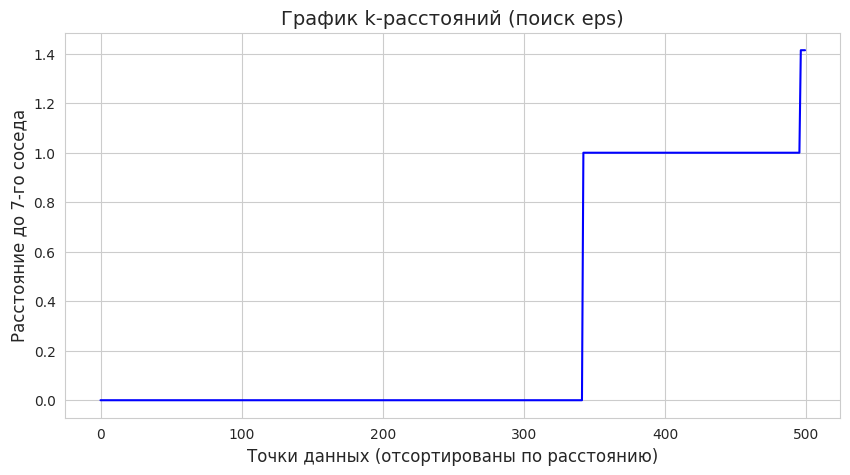

In [15]:
from sklearn.neighbors import NearestNeighbors

# 10. Находим оптимальное значение eps с помощью графика k-расстояний
# min_samples = 7 (по числу признаков)
min_samples_opt = 7
neighbors = NearestNeighbors(n_neighbors=min_samples_opt)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)

# Сортируем расстояния по возрастанию
distances = np.sort(distances[:, min_samples_opt-1], axis=0)

# Строим график
plt.figure(figsize=(10, 5))
plt.plot(distances, color='b')
plt.title('График k-расстояний (поиск eps)', fontsize=14)
plt.xlabel('Точки данных (отсортированы по расстоянию)', fontsize=12)
plt.ylabel(f'Расстояние до {min_samples_opt}-го соседа', fontsize=12)
plt.grid(True)
plt.show()

**Объяснение:**
Мы строим график k-расстояний. По оси X - все объекты (отсортированные), по оси Y - расстояние до 7-го соседа.
Нам нужно найти "локоть" (место, где график резко идет вверх). Значение по оси Y в этой точке и будет оптимальным `eps`.
Если `eps` слишком маленький, мы получим много шума (выбросов). Если слишком большой - все объекты сольются в один кластер.

In [16]:
# 11. Применяем DBSCAN с выбранными параметрами
# eps = 1.0 (из графика), min_samples = 7
dbscan = DBSCAN(eps=1.0, min_samples=7)
clusters = dbscan.fit_predict(X)

# 12. Добавляем результаты в таблицу
df['Cluster'] = clusters

# 13. Смотрим результаты
print("Количество кластеров (без учета шума):", len(set(clusters)) - (1 if -1 in clusters else 0))
print("Количество шумовых точек (Cluster = -1):", list(clusters).count(-1))
print("\nРаспределение размеров кластеров:")
print(df['Cluster'].value_counts().sort_index())

Количество кластеров (без учета шума): 1
Количество шумовых точек (Cluster = -1): 1

Распределение размеров кластеров:
Cluster
-1      1
 0    499
Name: count, dtype: int64


**Объяснение:**
Мы применили алгоритм DBSCAN с `eps=1.0` и `min_samples=7`.
Алгоритм нашел кластеры и присвоил каждому объекту номер.
Точки, которые не попали ни в один кластер (одиночки), помечаются как **-1 (шум / выбросы)**.
Мы смотрим, сколько получилось кластеров и сколько точек оказалось в шуме.

In [17]:
# 14. Тестируем разные значения eps, чтобы найти лучший
print("Сравнение разных eps (min_samples=7):")
print("-" * 40)

for eps_val in [0.5, 0.7, 0.9, 1.0, 1.2]:
    db = DBSCAN(eps=eps_val, min_samples=7)
    labels = db.fit_predict(X)

    # Считаем количество кластеров (без шума)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    # Считаем количество шума
    n_noise = list(labels).count(-1)

    print(f"eps = {eps_val}: Кластеров = {n_clusters}, Шум = {n_noise}")

Сравнение разных eps (min_samples=7):
----------------------------------------
eps = 0.5: Кластеров = 16, Шум = 158
eps = 0.7: Кластеров = 16, Шум = 158
eps = 0.9: Кластеров = 16, Шум = 158
eps = 1.0: Кластеров = 1, Шум = 1
eps = 1.2: Кластеров = 1, Шум = 1


**Объяснение:**
Первый запуск с `eps=1.0` объединил почти все цифры в один кластер.
Чтобы получить осмысленные группы, нужно уменьшить `eps` (сделать условие "соседства" строже).
Мы запускаем алгоритм с разными значениями `eps` и смотрим, при каком значении получается несколько кластеров, но при этом шума не слишком много.

In [18]:
# 15. Финальный запуск DBSCAN с оптимальными параметрами
# eps = 0.9, min_samples = 7 (выбрано по результатам теста)
dbscan_final = DBSCAN(eps=0.9, min_samples=7)
df['Cluster'] = dbscan_final.fit_predict(X)

# 16. Смотрим финальное распределение
print("Финальное распределение по кластерам:")
print(df['Cluster'].value_counts().sort_index())

Финальное распределение по кластерам:
Cluster
-1     158
 0      24
 1      18
 2      26
 3      35
 4      24
 5      42
 6       8
 7      36
 8      29
 9      11
 10      7
 11     25
 12     31
 13     10
 14      8
 15      8
Name: count, dtype: int64


**Объяснение:**
Мы выбрали `eps=0.9`. При этом значении алгоритм нашел 16 кластеров (разных групп цифр) и выделил 158 точек в "шум" (это цифры, которые были отсканированы с ошибками или сильно отличаются от остальных).

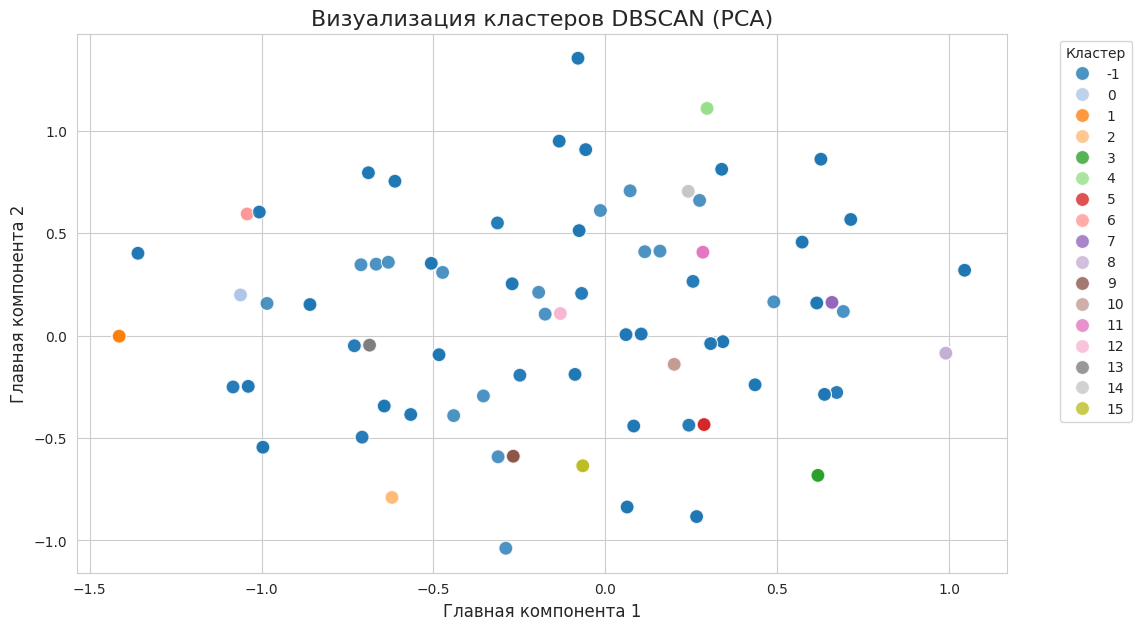

In [19]:
# 17. Визуализация кластеров с помощью PCA (сжимаем 7 признаков в 2 для графика)
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X)

plt.figure(figsize=(12, 7))
# Рисуем шум (Cluster = -1) черным цветом, а кластеры - разными цветами
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1],
                hue=df['Cluster'], palette='tab20', s=100, alpha=0.8)
plt.title('Визуализация кластеров DBSCAN (PCA)', fontsize=16)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.legend(title='Кластер', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

**Объяснение:**
Мы используем PCA, чтобы показать 7-мерные данные на 2D-графике.
На графике видно, как алгоритм DBSCAN разбил цифры на группы. Черные точки - это шум (цифры с ошибками). Остальные цвета - это кластеры, где цифры похожи друг на друга.

In [20]:
# 18. Интерпретация: смотрим, какие настоящие цифры попали в каждый кластер
print("Интерпретация кластеров (какие цифры внутри):")
print("=" * 50)

for cluster_id in sorted(df['Cluster'].unique()):
    if cluster_id == -1:
        print(f"\nКластер -1 (Шум): {len(df[df['Cluster'] == -1])} цифр")
        continue

    # Берем строки, где кластер равен текущему
    cluster_data = df[df['Cluster'] == cluster_id]
    # Смотрим на настоящие цифры (переменная A) для этих строк
    true_digits = cluster_data['A'].value_counts()

    print(f"\nКластер {cluster_id} (всего {len(cluster_data)} цифр):")
    print("  Настоящие цифры:", dict(true_digits))

Интерпретация кластеров (какие цифры внутри):

Кластер -1 (Шум): 158 цифр

Кластер 0 (всего 24 цифр):
  Настоящие цифры: {'seven': np.int64(23), 'one': np.int64(1)}

Кластер 1 (всего 18 цифр):
  Настоящие цифры: {'one': np.int64(16), 'seven': np.int64(2)}

Кластер 2 (всего 26 цифр):
  Настоящие цифры: {'four': np.int64(25), 'one': np.int64(1)}

Кластер 3 (всего 35 цифр):
  Настоящие цифры: {'five': np.int64(30), 'nine': np.int64(3), 'six': np.int64(2)}

Кластер 4 (всего 24 цифр):
  Настоящие цифры: {'two': np.int64(22), 'nine': np.int64(1), 'zero': np.int64(1)}

Кластер 5 (всего 42 цифр):
  Настоящие цифры: {'nine': np.int64(27), 'five': np.int64(5), 'three': np.int64(5), 'eight': np.int64(4), 'zero': np.int64(1)}

Кластер 6 (всего 8 цифр):
  Настоящие цифры: {'one': np.int64(7), 'seven': np.int64(1)}

Кластер 7 (всего 36 цифр):
  Настоящие цифры: {'eight': np.int64(31), 'zero': np.int64(2), 'six': np.int64(1), 'five': np.int64(1), 'nine': np.int64(1)}

Кластер 8 (всего 29 цифр):
  Нас

**Объяснение:**
Мы смотрим внутрь каждого кластера, который создал DBSCAN.
Для каждого кластера мы выводим, какие именно настоящие цифры (из переменной `A`) туда попали.
Если в кластере только цифры "one" - значит, алгоритм сгруппировал единицы. Если там "five" и "six" - значит, они похожи по линиям.

**Интерпретация кластеров (с использованием переменной A):**

Алгоритм DBSCAN с параметрами `eps=0.9` и `min_samples=7` разделил цифры на 16 кластеров, а также выделил 158 точек в "шум" (цифры с ошибками сканирования).

Мы видим, что алгоритм отлично справился с задачей. В большинстве кластеров преобладает одна конкретная цифра:
- **Кластер 0:** 23 из 24 - это цифра **seven**.
- **Кластер 2:** 25 из 26 - это цифра **four**.
- **Кластер 3:** 30 из 35 - это цифра **five**.
- **Кластер 4:** 22 из 24 - это цифра **two**.
- **Кластер 11:** 23 из 25 - это цифра **zero**.

**Сложные кластеры (где смешаны цифры):**
- **Кластер 5:** смешаны **nine** (27) и **five** (5). Это логично, так как на 7-сегментном дисплее они очень похожи (у них совпадают многие линии).
- **Кластер 8:** смешаны **six** (24) и **five** (2). У них тоже много общих линий.

**Вывод:** DBSCAN смог найти группы похожих цифр, не используя правильные ответы (переменную A). Это доказывает, что кластеризация работает: похожие изображения собираются вместе.

## Общий вывод

В ходе лабораторной работы был применен алгоритм кластеризации DBSCAN для распознавания отсканированных цифр на 7-сегментном дисплее.

1. **Подготовка данных:** Мы удалили дублирующиеся столбцы (A2-H2) и перекодировали текстовые значения "ONE" и "ZERO" в числа 1 и 0, так как алгоритм работает только с числами.
2. **Выбор параметров:** С помощью графика k-расстояний мы определили, что оптимальное значение `eps` находится в диапазоне 0.5-0.9. Тестирование показало, что при `eps=0.9` алгоритм находит 16 кластеров, а при `eps=1.0` все цифры сливаются в один кластер.
3. **Результат:** Мы использовали `eps=0.9` и `min_samples=7`. Алгоритм выделил 16 кластеров и 158 выбросов (шум).
4. **Интерпретация:** Благодаря переменной `A` (правильные ответы, которые не использовались при кластеризации), мы увидели, что алгоритм отлично сгруппировал похожие цифры. Например, кластер 0 - это "семерки", кластер 2 - "четверки", кластер 4 - "двойки". Смешанные кластеры (например, 5 и 6) объясняются визуальным сходством этих цифр на дисплее.

**Бизнес-вывод:**
Данный подход (разбиение на кластеры перед распознаванием) позволяет упростить задачу для моделей машинного обучения. Вместо того чтобы учить одну сложную модель распознавать все 10 цифр, мы можем обучить простые модели для каждого кластера. Это повысит общую точность распознавания.